# Import setup variables

In [1]:
#%pip install --upgrade google-api-core google-cloud-bigquery pandas-gbq grpcio grpcio-status

In [2]:
import subprocess
import sys

import numpy as np
import pandas as pd
import os
import seaborn as sns
from pathlib import Path
import glob
from google.cloud.bigquery.schema import DataPolicy
import pandas_gbq
from scipy.optimize import minimize

exec(open("./PGS_calc_param.txt").read())

# Read in genetic PCs

In [3]:
import json
ancestry_file = "/home/jupyter/workspace/vwb-aou-datasets-controlled/v9/wgs/short_read/snpindel/aux/ancestry/ancestry_preds.tsv"
ancestry = pd.read_csv(ancestry_file, sep="\t", converters={"pca_features": json.loads})

In [4]:
# Make PC columns 
pc = pd.DataFrame([pd.Series(x) for x in ancestry.pca_features])
pc.columns = ['PC_{}'.format(x+1) for x in pc.columns]

# Add PC columns back to dataframe 
ancestry = pd.concat([ancestry, pc], axis=1)
ancestry.rename(columns={ancestry.columns[0]: "person_id"}, inplace=True)

# Split out training data 

If a sample_id file is not provided, those without EHR data will be used to train the PRS

In [5]:
dataset_id='C2024Q3R9'
dataset=!wb resolve --id {dataset_id} 
dataset_str = dataset[0]
os.environ['WORKSPACE_CDR'] = dataset_str
CDR_version = os.getenv("WORKSPACE_CDR")

# Set up EHR querys
query_condition="""SELECT person_id, min(condition_start_date) as min_cond_date,max(condition_start_date)as max_cond_date,
COUNT(DISTINCT condition_concept_id) as cond_code_cnt, COUNT(DISTINCT visit_occurrence_id) as num_cond_visits
FROM `"""+CDR_version+""".condition_occurrence` WHERE condition_start_date >='1880-01-01'
GROUP BY person_id """
query_observation = ("""
    SELECT distinct person_id, min(observation_date) as min_obs_date, max(observation_date) as max_obs_date, 
    COUNT(DISTINCT observation_concept_id) as observation_code_cnt, COUNT(DISTINCT visit_occurrence_id) as num_obs_visits
    FROM 
        (SELECT DISTINCT person_id, observation_source_concept_id, observation_source_value, 
        observation_date, observation_concept_id, visit_occurrence_id
            FROM `"""+ str(CDR_version) +""".observation`) AS obs
            INNER JOIN 
            (SELECT DISTINCT concept_id, concept_name, concept_code, vocabulary_id 
                    FROM `"""+str(CDR_version)+""".concept`
                    where (vocabulary_id ='ICD9CM') or 
                (vocabulary_id ='ICD10CM')) as concept 
                on concept.concept_id = obs.observation_source_concept_id
    group by person_id
    """)


################# Use sample id file if available ################# 
sample_id_file = os.getenv("SAMPLE_ID_FILE", "").strip()

if sample_id_file:
    sample_ids = pd.read_csv(sample_id_file)["person_id"].tolist()

################# Else, use EHR exclusion ################# 
else:
    sample_ids = None  # Use the default: all sample IDs without EHR data
    print("No sample ID file, using EHR exclusion") 
    # first query from condition occurrence to get number of distinct codes and ehr length
    ehr_covariate=pandas_gbq.read_gbq(query_condition, dialect="standard")
    observation_code_dates = pandas_gbq.read_gbq(query_observation, dialect="standard")
    ehr_covariate_plus = pd.merge(observation_code_dates, ehr_covariate, on="person_id", how = 'outer')
    sample_ids = ehr_covariate_plus["person_id"].tolist()

No sample ID file, using EHR exclusion
Downloading: 100%|██████████|
Downloading: 100%|██████████|


# Make training and testing cohorts

In [6]:
test_pcs_df = ancestry[ancestry['person_id'].isin(sample_ids)]
train_pcs_df = ancestry[~ancestry['person_id'].isin(sample_ids)]

## Downsample training cohort

In [7]:
# --- Print ancestry distribution before sampling ---
print("Before sampling:")
ancestry_counts = train_pcs_df["ancestry_pred"].value_counts()
print(ancestry_counts)

# --- Stratified downsampling to second smallest group ---
np.random.seed(246)

second_smallest_n = ancestry_counts.sort_values().iloc[1]

print(f"Downsampling each ancestry group to n={second_smallest_n}")

train_pcs_df = (
    train_pcs_df.groupby("ancestry_pred", group_keys=False)
    .apply(lambda x: x.sample(n=min(second_smallest_n, len(x)), replace=False))
)

# --- 7. Check result ---
print("After sampling:")
print(train_pcs_df['ancestry_pred'].value_counts())

Before sampling:
ancestry_pred
eur    117387
amr     50482
afr     42065
eas      8488
sas      3241
mid       895
Name: count, dtype: int64
Downsampling each ancestry group to n=3241
After sampling:
ancestry_pred
afr    3241
amr    3241
eas    3241
eur    3241
sas    3241
mid     895
Name: count, dtype: int64


/tmp/ipykernel_878/1997095095.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(second_smallest_n, len(x)), replace=False))


# Functions to adjust PRS for genetic PCs

In [8]:
# function to extract pcs (+ 1 vec) and scores as numpy arrays
def extract_pcs_and_scores(df, pc_indices):
    pcs_np = df[[f'PC_{i}' for i in pc_indices]].to_numpy()
    n_rows = pcs_np.shape[0]
    pcs_np = np.append(np.repeat(1, n_rows).reshape(n_rows, 1), pcs_np, axis = 1)
    scores = df['SCORE_AVG'].to_numpy()
    return pcs_np, scores

def extract_standardized_pcs_and_scores(df, pc_indices):
    pcs_np = df[[f'PC_{i}' for i in pc_indices]].to_numpy()
    pcs_np = (pcs_np - np.mean(pcs_np, axis = 0))/np.std(pcs_np, axis = 0)
    n_rows = pcs_np.shape[0]
    pcs_np = np.append(np.repeat(1, n_rows).reshape(n_rows, 1), pcs_np, axis = 1)
    scores = df['SCORE_AVG'].to_numpy()
    return pcs_np, scores

# function to predict mean
def f_mu(pcs, theta):
    return np.dot(pcs, theta)

# function to predict variance
def f_var(pcs, theta):
    return np.exp(np.dot(pcs, theta))

# objective function
# returns loss, gradient
def obj(pcs, scores, theta):
    split_index = pcs.shape[1]
    
    theta_mu = theta[:split_index]
    theta_var = theta[split_index:]
    mu = f_mu(pcs, theta_mu)
    var = f_var(pcs, theta_var)
    # loss is - log of normal distribution (with constant log sqrt(2pi) removed)
    loss = np.sum(np.log(np.sqrt(var)) + (1/2)*(scores-mu)**2/var)
    
    #gradient of loss
    mu_coeff = -(scores-mu)/var
    sig_coeff = 1/2 - (1/2)*(scores-mu)**2/var
    grad = np.append(np.sum(pcs * mu_coeff[:,np.newaxis], axis=0), np.sum(pcs * sig_coeff[:, np.newaxis], axis=0))
    
    return loss, grad

def obj_L1(pcs, scores, theta, l):
    unreg_loss, unreg_grad = obj(pcs, scores, theta)
    loss = unreg_loss + l*np.sum(np.abs(theta))
    grad = unreg_grad + l*np.sign(theta)
    return loss, grad

def adjust_scores(pcs, scores, theta):
    split_index = pcs.shape[1]
    
    theta_mu = theta[:split_index]
    theta_var = theta[split_index:]
    mu = f_mu(pcs, theta_mu)
    var = f_var(pcs, theta_var)
    
    adjusted_scores = (scores - mu)/np.sqrt(var)
    return adjusted_scores

## Load in calculated PGS

In [9]:
env_path = "/home/jupyter/workspace/workspace-bucket/calculate_pgs/plink_results/latest_run.env"

with open(env_path) as f:
    for line in f:
        line = line.strip()
        if line and not line.startswith("#"):
            key, value = line.split("=", 1)
            os.environ[key] = value.strip('"').strip("'")

PGS = os.environ["PGS"]
PGS_IDs = PGS.split('\\ ')
RUN_ID = os.environ["RUN_ID"]
OUTPUT_PATH = os.environ["OUTPUT_PATH"]

#PGS_df = pd.read_csv(f"{OUTPUT_PATH}/{PGS}_combined_chr1_22_{RUN_ID}.csv")
#PGS_df.rename(columns={PGS_df.columns[0]: "person_id"}, inplace=True)

In [10]:
n_pcs = 16
pre_adjusted_plot_data = []
post_adjusted_plot_data_training = []
post_adjusted_plot_data_testing = []

for PGS_ID in PGS_IDs:
    print(PGS_ID)
    PGS_df = pd.read_csv(f"{OUTPUT_PATH}/{PGS_ID}_combined_chr1_22_{RUN_ID}.csv")
    PGS_df.rename(columns={PGS_df.columns[1]: "person_id"}, inplace=True)

    PGS_df_indexed = PGS_df.set_index("person_id")
    train_pcs_indexed = train_pcs_df.set_index("person_id")
    test_pcs_indexed = test_pcs_df.set_index("person_id")
    
    train_scores_and_pcs = PGS_df_indexed.join(train_pcs_indexed, how="inner")
    test_scores_and_pcs = PGS_df_indexed.join(test_pcs_indexed, how="inner")

    train_pcs, train_scores = extract_pcs_and_scores(train_scores_and_pcs, range(1, n_pcs + 1))
    x0 = np.append(np.append(train_scores.mean(), np.repeat(0, n_pcs)), 
                np.append(np.log(train_scores.var()), np.repeat(0, n_pcs))
                )
    res = minimize(lambda theta : obj(train_pcs, train_scores, theta), x0, method="BFGS", jac=True)
    test_pcs, test_scores = extract_pcs_and_scores(test_scores_and_pcs, range(1, n_pcs + 1))
    
    adjusted_train_scores = adjust_scores(train_pcs, train_scores, res.x)
    adjusted_test_scores = adjust_scores(test_pcs, test_scores, res.x)
    
    df_train_adjusted = train_scores_and_pcs.copy()[["ancestry_pred", "SCORE_AVG"]]
    df_train_adjusted["adjusted_score"] = adjusted_train_scores
    
    df_test_adjusted = test_scores_and_pcs.copy()[["ancestry_pred", "SCORE_AVG"]]
    df_test_adjusted["adjusted_score"] = adjusted_test_scores

    print("Number of samples in test dataframe:", len(df_test_adjusted))

    OUTPUT_PATH = Path(OUTPUT_PATH)

    filename = f"{PGS}_final_adjusted_{RUN_ID}.csv"
    df_test_adjusted.to_csv(
        OUTPUT_PATH / filename,
        sep=","
    )

    plot_df = df_train_adjusted[["ancestry_pred", "SCORE_AVG"]].copy()
    plot_df["PGS_ID"] = PGS_ID
    pre_adjusted_plot_data.append(plot_df)

    plot_df = df_train_adjusted[["ancestry_pred", "adjusted_score"]].copy()
    plot_df["PGS_ID"] = PGS_ID
    post_adjusted_plot_data_training.append(plot_df)

    plot_df = df_test_adjusted[["ancestry_pred", "adjusted_score"]].copy()
    plot_df["PGS_ID"] = PGS_ID
    post_adjusted_plot_data_testing.append(plot_df)

    
 

PGS000662
Number of samples in test dataframe: 286164
PGS000004
Number of samples in test dataframe: 286164
PGS003446
Number of samples in test dataframe: 286164
PGS002727
Number of samples in test dataframe: 286164
PGS002308
Number of samples in test dataframe: 286164
PGS002810
Number of samples in test dataframe: 286164
PGS000014
Number of samples in test dataframe: 286164
PGS000020
Number of samples in test dataframe: 286164
PGS000031
Number of samples in test dataframe: 286164
PGS000032
Number of samples in test dataframe: 286164
PGS000033
Number of samples in test dataframe: 286164
PGS000036
Number of samples in test dataframe: 286164
PGS000125
Number of samples in test dataframe: 286164
PGS000330
Number of samples in test dataframe: 286164
PGS000712
Number of samples in test dataframe: 286164


# Plot PRS distributions by ancestry groups pre and post adjustment

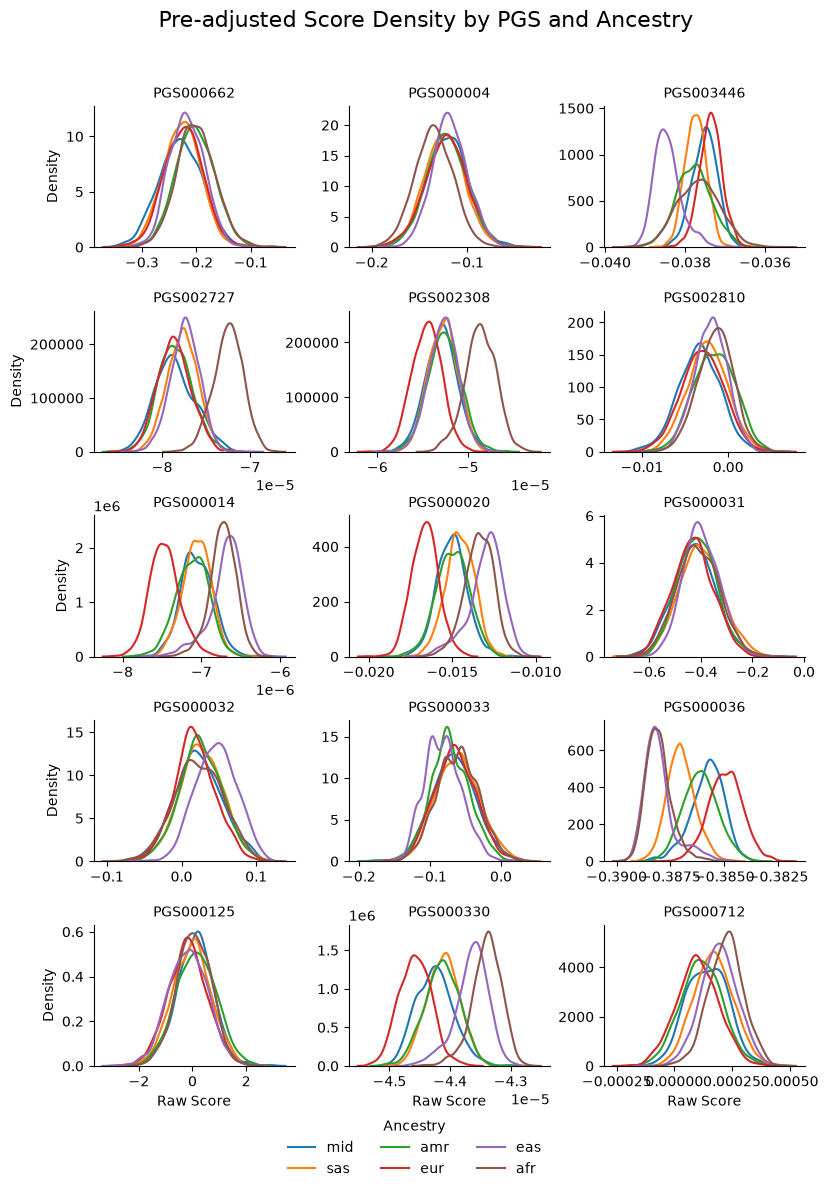

Saved plot to: /home/jupyter/workspace/workspace-bucket/calculate_pgs/plink_results/PGS000662_PGS000004_PGS003446_PGS002727_PGS002308_PGS002810_PGS000014_PGS000020_PGS000031_PGS000032_PGS000033_PGS000036_PGS000125_PGS000330_PGS000712_GRCh38_20261111_191354/pre_adjusted_score_density_all_PGS.png


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

all_pre_adjusted = pd.concat(pre_adjusted_plot_data, ignore_index=True)

g = sns.FacetGrid(
    all_pre_adjusted,
    col="PGS_ID",
    col_wrap=3,
    hue="ancestry_pred",
    sharex=False,
    sharey=False
)

g.map_dataframe(
    sns.kdeplot,
    x="SCORE_AVG",
    common_norm=False,
)

g.add_legend(title="Ancestry",  loc="lower center", ncol=3)
g.set_axis_labels("Raw Score", "Density")
g.set_titles("{col_name}")
g.fig.suptitle("Pre-adjusted Score Density by PGS and Ancestry", fontsize=16)
g.fig.tight_layout()
g.fig.subplots_adjust(top=0.9, hspace=0.45, bottom=0.1)
g.fig.set_size_inches(8, (len(PGS_IDs)*2/3)+2)

OUTPUT_PATH = Path(OUTPUT_PATH)
filename = "pre_adjusted_score_density_all_PGS.png"
g.savefig(OUTPUT_PATH / filename, dpi=300, bbox_inches="tight")
plt.show()
plt.close(g.fig)

print(f"Saved plot to: {OUTPUT_PATH / filename}")

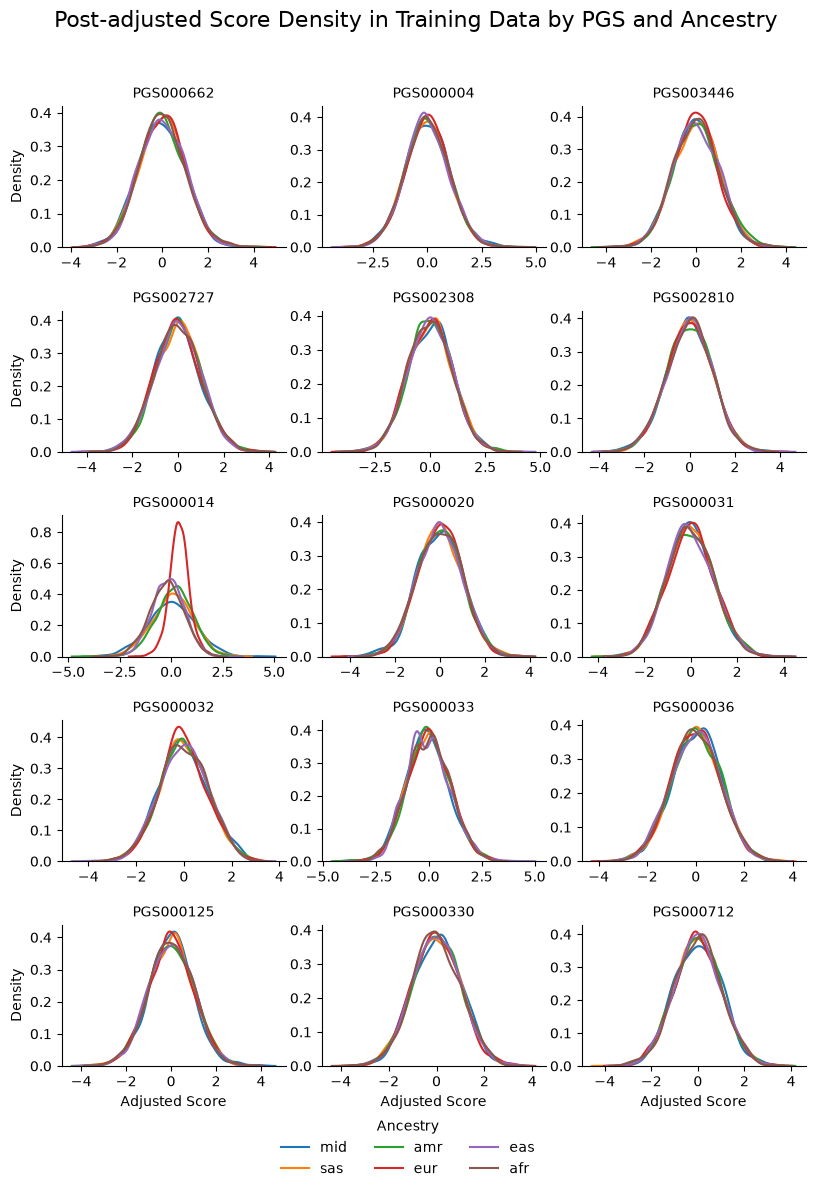

Saved plot to: /home/jupyter/workspace/workspace-bucket/calculate_pgs/plink_results/PGS000662_PGS000004_PGS003446_PGS002727_PGS002308_PGS002810_PGS000014_PGS000020_PGS000031_PGS000032_PGS000033_PGS000036_PGS000125_PGS000330_PGS000712_GRCh38_20261111_191354/post_adjusted_score_density_all_PGS_training_data.png


In [15]:
all_post_adjusted_training = pd.concat(post_adjusted_plot_data_training, ignore_index=True)

g = sns.FacetGrid(
    all_post_adjusted_training,
    col="PGS_ID",
    col_wrap=3,
    hue="ancestry_pred",
    sharex=False,
    sharey=False
)

g.map_dataframe(
    sns.kdeplot,
    x="adjusted_score",
    common_norm=False,
)

g.add_legend(title="Ancestry",  loc="lower center", ncol=3)
g.set_axis_labels("Adjusted Score", "Density")
g.set_titles("{col_name}")
g.fig.suptitle("Post-adjusted Score Density in Training Data by PGS and Ancestry", fontsize=16)
g.fig.tight_layout()
g.fig.subplots_adjust(top=0.9, hspace=0.45, bottom=0.1)
g.fig.set_size_inches(8, (len(PGS_IDs)*2/3)+2)

OUTPUT_PATH = Path(OUTPUT_PATH)
filename = "post_adjusted_score_density_all_PGS_training_data.png"
g.savefig(OUTPUT_PATH / filename, dpi=300, bbox_inches="tight")
plt.show()
plt.close(g.fig)

print(f"Saved plot to: {OUTPUT_PATH / filename}")


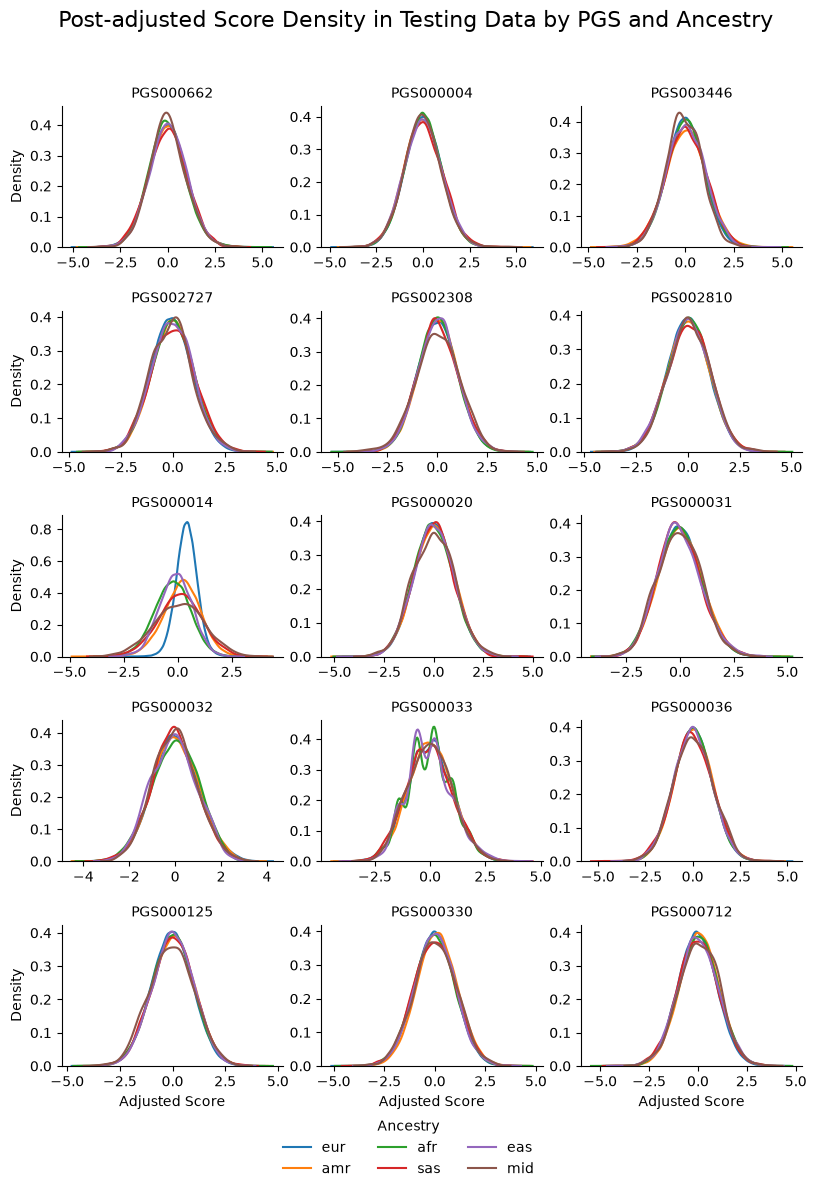

Saved plot to: /home/jupyter/workspace/workspace-bucket/calculate_pgs/plink_results/PGS000662_PGS000004_PGS003446_PGS002727_PGS002308_PGS002810_PGS000014_PGS000020_PGS000031_PGS000032_PGS000033_PGS000036_PGS000125_PGS000330_PGS000712_GRCh38_20261111_191354/post_adjusted_score_density_all_PGS_testing_data.png


In [16]:
all_post_adjusted_testing = pd.concat(post_adjusted_plot_data_testing, ignore_index=True)

g = sns.FacetGrid(
    all_post_adjusted_testing,
    col="PGS_ID",
    col_wrap=3,
    hue="ancestry_pred",
    sharex=False,
    sharey=False
)

g.map_dataframe(
    sns.kdeplot,
    x="adjusted_score",
    common_norm=False,
)

g.add_legend(title="Ancestry",  loc="lower center", ncol=3)
g.set_axis_labels("Adjusted Score", "Density")
g.set_titles("{col_name}")
g.fig.suptitle("Post-adjusted Score Density in Testing Data by PGS and Ancestry", fontsize=16)
g.fig.tight_layout()
g.fig.subplots_adjust(top=0.9, hspace=0.45, bottom=0.1)
g.fig.set_size_inches(8, (len(PGS_IDs)*2/3)+2)

OUTPUT_PATH = Path(OUTPUT_PATH)
filename = "post_adjusted_score_density_all_PGS_testing_data.png"
g.savefig(OUTPUT_PATH / filename, dpi=300, bbox_inches="tight")
plt.show()
plt.close(g.fig)

print(f"Saved plot to: {OUTPUT_PATH / filename}")
